# Spaceship Titanic Kaggle Competition

Goal: Predict passengers who were transported to another dimension due to a spacetime anomaly. The `Transported` value is to be predicted for the passengers in the testing set.

- train.csv - Personal records for about two-thirds (~8700) of the passengers. This is the training data.
- test.csv  - Personal records for the remaining one-third (~4300) of the passengers. This is the testing data.

## Field Descriptions

- **PassengerId** - A unique Id for each passenger. Each Id takes the form gggg_pp where gggg indicates a group the passenger is travelling with and pp is their number within the group. People in a group are often family members, but not always.
- **HomePlanet** - The planet the passenger departed from, typically their planet of permanent residence.
- **CryoSleep** - Indicates whether the passenger elected to be put into suspended animation for the duration of the voyage. Passengers in cryosleep are confined to their cabins.
- **Cabin** - The cabin number where the passenger is staying. Takes the form deck/num/side, where side can be either P for Port or S for Starboard.
- **Destination** - The planet the passenger will be debarking to.
- **Age** - The age of the passenger.
- **VIP** - Whether the passenger has paid for special VIP service during the voyage.
- **RoomService, FoodCourt, ShoppingMall, Spa, VRDeck** - Amount the passenger has billed at each of the Spaceship Titanic's many luxury amenities.
- **Name** - The first and last names of the passenger.
- **Transported** - Whether the passenger was transported to another dimension. This is the target, the column you are trying to predict.

## What this Notebook Covers
1. Exploratory Data Analysis (EDA)
2. Feature Engineering
3. Data Cleaning and Preprocessing (Encoding and Scaling)
4. Training ML Models
5. Cross Validation and Esemble Predictions

## Evaluation Metric

The evaluation metric is the classification accuracy, which is the percentage of predicted labels that are correct.

The formula for classification accuracy is:

$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
$$

- TP (True Positives): Correctly predicted positive cases
- TN (True Negatives): Correctly predicted negative cases
- FP (False Positives): Incorrectly predicted positive cases (Type I error)
- FN (False Negative): Incorrectly predicted negative cases (Type II error)

Currently following this guide on Spaceship Titanic: [Guide](https://www.kaggle.com/code/samuelcortinhas/spaceship-titanic-a-complete-guide/notebook)

## 1. Required Imports

In [1]:
# basic imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

CYAN, NAVY, TEAL, SAND, RED, GREY = "#00FFFF", "#16324a", "#2f8f83", "#d2b587", "#c4573f", "#9aa7b0"

## 2. Exploratory Data Analysis

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

In [3]:
train.head(5)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [4]:
print(f"Training Set - (Rows: {train.shape[0]}, Columns: {train.shape[1]})")

Training Set - (Rows: 8693, Columns: 14)


In [5]:
print(train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB
None


In [6]:
train["Transported"].value_counts(normalize=True)

Transported
True     0.503624
False    0.496376
Name: proportion, dtype: float64

Checking for duplicates

In [7]:
print(f'Duplicates in train set: {train.duplicated().sum()}, ({np.round(100*train.duplicated().sum()/len(train),1)}%)')

Duplicates in train set: 0, (0.0%)


In [8]:
train.nunique()

PassengerId     8693
HomePlanet         3
CryoSleep          2
Cabin           6560
Destination        3
Age               80
VIP                2
RoomService     1273
FoodCourt       1507
ShoppingMall    1115
Spa             1327
VRDeck          1306
Name            8473
Transported        2
dtype: int64

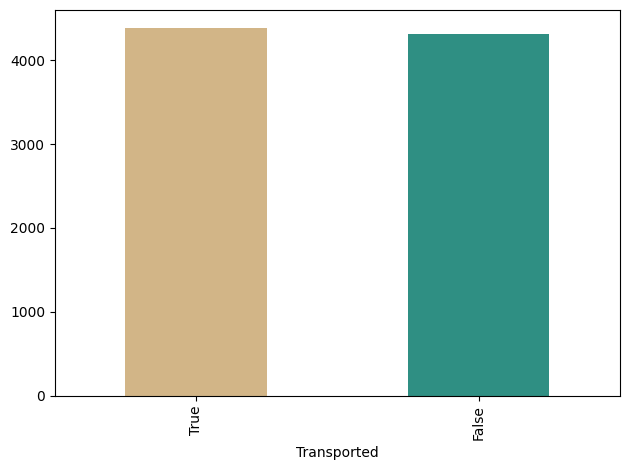

In [9]:
train["Transported"].value_counts().plot(kind="bar", color=[SAND, TEAL])
plt.tight_layout()
plt.show()

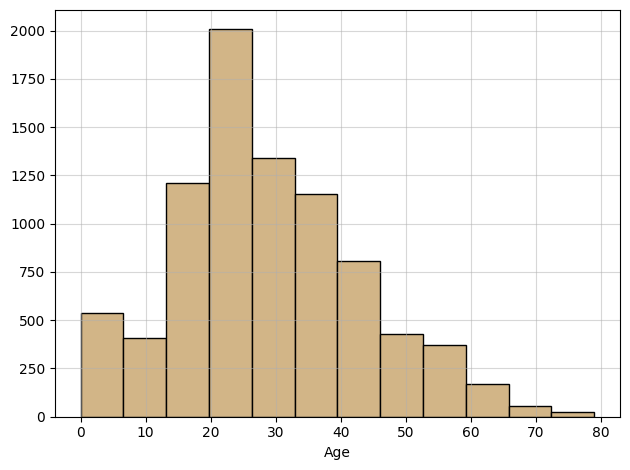

In [10]:
train["Age"].hist(edgecolor="black", bins=12, color=SAND)
plt.grid(True, alpha=0.5)
plt.xlabel("Age")
plt.tight_layout()
plt.show()

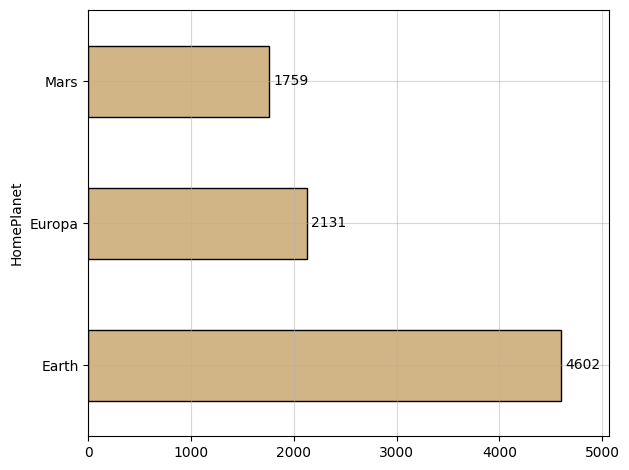

In [11]:
fig, ax = plt.subplots()

counts = train["HomePlanet"].value_counts()
counts.plot(kind="barh", color=SAND, edgecolor="black", ax=ax)

ax.bar_label(ax.containers[0], padding=3)   
ax.set_xlim(0, counts.max() * 1.1)    

plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

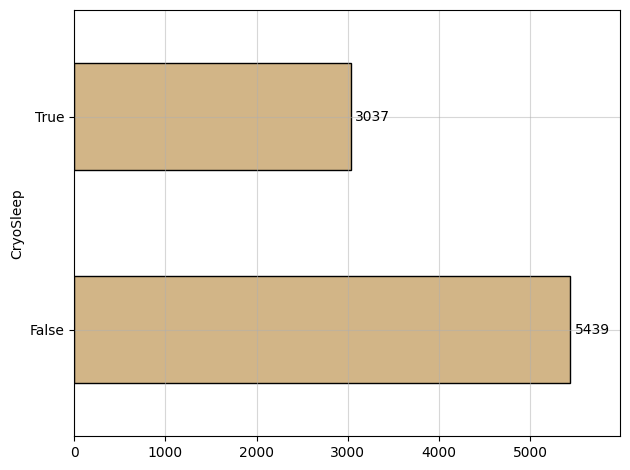

In [12]:
fig, ax = plt.subplots()

counts = train["CryoSleep"].value_counts()
counts.plot(kind="barh", color=SAND, edgecolor="black", ax=ax)

ax.bar_label(ax.containers[0], padding=3)   
ax.set_xlim(0, counts.max() * 1.1)          

ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

Text(0.5, 0, 'Age (years)')

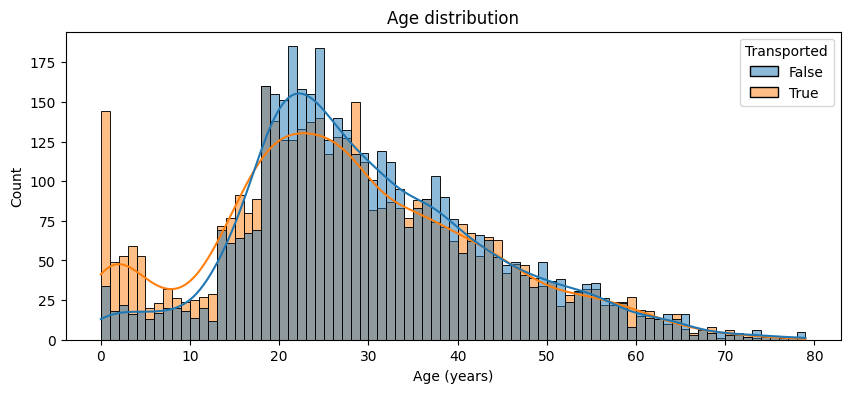

In [13]:
# Figure size
plt.figure(figsize=(10,4))

# Histogram
sns.histplot(data=train, x='Age', hue='Transported', binwidth=1, kde=True)

# Aesthetics
plt.title('Age distribution')
plt.xlabel('Age (years)')

### Insights

Based off the histogram, 0-18 year olds were more likely to be transported than not. 18-25 year olds were less likely to be transported than not. Finally people 25 years or older were equally likely to be transported than those who were not.

A new feature should be engineered to indicate whether the passenger was a child, adolescent, or adult.

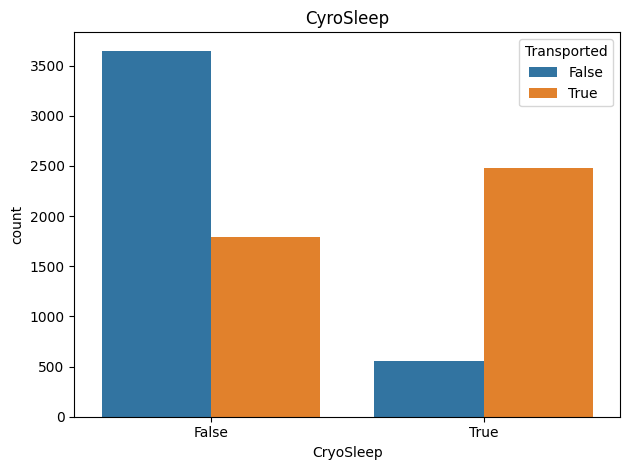

In [14]:
# A count plot is like a histogram but used for categorical variables
sns.countplot(data=train, x="CryoSleep", hue="Transported")

plt.title("CyroSleep")
plt.tight_layout()
plt.show()

### Insights

Based on this histogram, passengers who were in Cryosleep were way more likely to be transported than those who were awake. CryoSleep seems to be a good feature for predicting whether or not a passenger was transported.

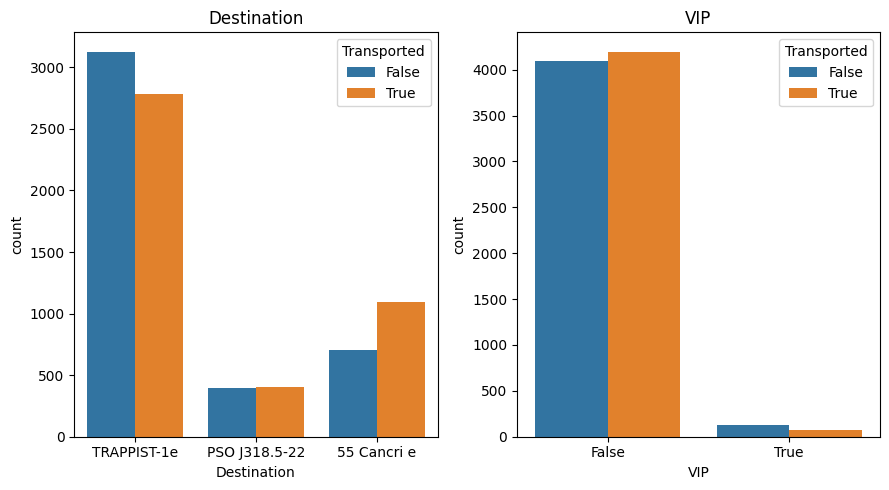

In [15]:
# A count plot is like a histogram but used for categorical variables
fig, axes = plt.subplots(1, 2, figsize=(9, 5))

sns.countplot(data=train, x="Destination", hue="Transported", ax=axes[0])
sns.countplot(data=train, x="VIP", hue="Transported", ax=axes[1])

axes[0].set_title("Destination")
axes[1].set_title("VIP")
plt.tight_layout()
plt.show()

### Insights

Destination and VIP seem to have equal target split, so these features are probably not very useful in determining transportation.

Qualitative Features

In [16]:
qual_feats = ['PassengerId', 'Cabin' ,'Name']
train[qual_feats].head()

,PassengerId,Cabin,Name
0,0001_01,B/0/P,Maham Ofracculy
1,0002_01,F/0/S,Juanna Vines
2,0003_01,A/0/S,Altark Susent
3,0003_02,A/0/S,Solam Susent
4,0004_01,F/1/S,Willy Santantines


# 3. Data Preparation

## Questions Worth Considering
1. How should missing values be handled?
   - Some possibilites include:
     - Imputing variables using K-Nearest Neighbors (KNN)
     - group-based conditional imputation
     - Take the median of a specific sub-population
2. What features can I create based off what I have?

In [17]:
train[:5]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


## Feature Engineering

Binning age into groups

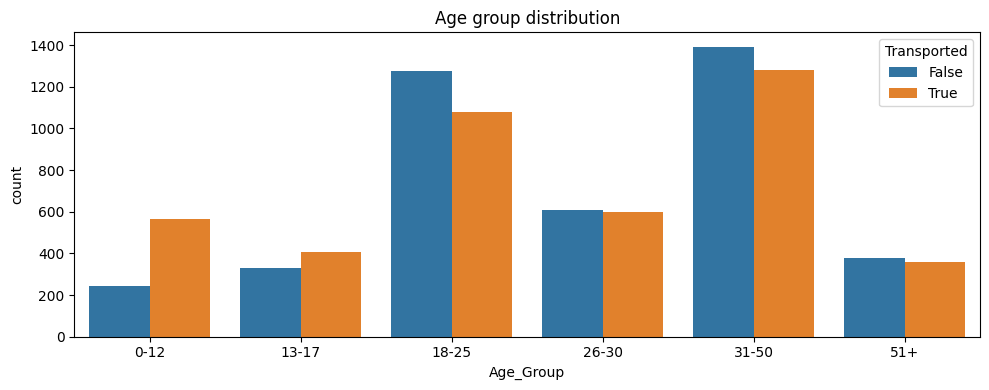

In [18]:
age_edges = [-np.inf, 12, 17, 25, 30, 50, np.inf]
age_labels = ["0-12", "13-17", "18-25", "26-30", "31-50", "51+"]
age_groups = pd.cut(
    train["Age"], age_edges, labels=age_labels
)

train["Age_Group"] = age_groups

# apply the age groups to the testing set
test["Age_Group"] = age_groups

plt.figure(figsize=(10,4))
g=sns.countplot(data=train, x='Age_Group', hue='Transported', order=age_labels)
plt.title('Age group distribution')

plt.tight_layout()
plt.show()

Calculating total spend and identifying passengers with zero spend

In [19]:
train["TotalSpend"] = train[["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]].sum(axis=1)
train["ZeroSpend"] = (train["TotalSpend"] == 0).astype(int)

# Create the new columns for the testing set as well
test["TotalSpend"] = test[["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]].sum(axis=1)
test["ZeroSpend"] = (test["TotalSpend"] == 0).astype(int)

Since PassengerId has a group identification number and the number they are within that group, passengerId can be split into Group and can also have a group size.

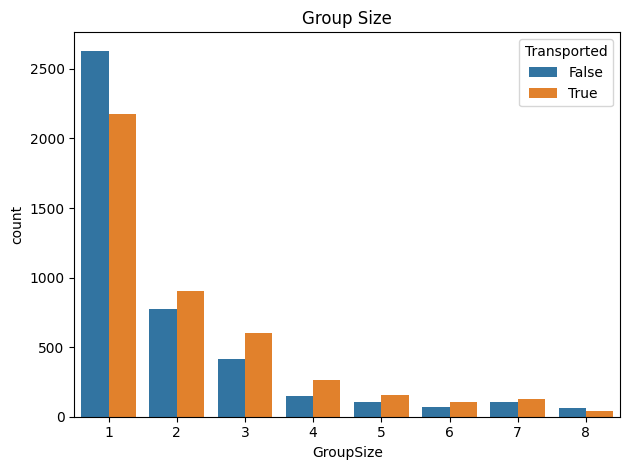

In [20]:
train["Group"] = train["PassengerId"].str[:4].astype(int)
test["Group"] = test["PassengerId"].str[:4].astype(int)

group_counts = pd.concat([train['Group'], test['Group']]).value_counts()

train['GroupSize'] = train['Group'].map(group_counts)
test['GroupSize'] = test['Group'].map(group_counts)

sns.countplot(data=train, x='GroupSize', hue='Transported')
plt.title('Group Size')

plt.tight_layout()
plt.show()

### Insights

Those who are traveling solo (GroupSize = 1), are less likely to be transported than those traveling with one or more people.

Creating a new feature for people who are traveling solo or not

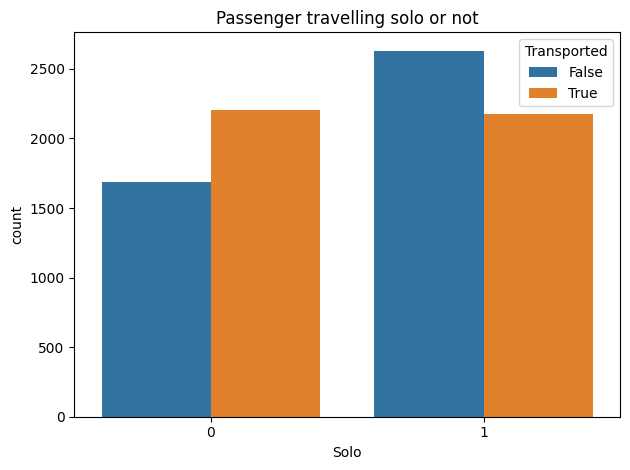

In [21]:
train['Solo'] = (train['GroupSize'] == 1).astype(int)
test['Solo'] = (test['GroupSize'] == 1).astype(int)

sns.countplot(data=train, x='Solo', hue='Transported')
plt.title('Passenger travelling solo or not')

plt.tight_layout()
plt.show()

Split the `Cabin` column into its individual parts (deck, num, and side). This will give us deck, num, and side as separate features.

In [22]:
train[["Deck", "CabinNum", "Side"]] = train["Cabin"].str.split("/", expand=True)

# applying same feature engineering to the testing set
test[["Deck", "CabinNum", "Side"]] = test["Cabin"].str.split("/", expand=True)

# Cabin is no longer needed so we can drop it
train = train.drop('Cabin', axis=1)
test = test.drop('Cabin', axis=1)

Calculate family size based on last name.

In [23]:
train['Surname'] = train['Name'].str.split().str[-1]
test['Surname'] = test['Name'].str.split().str[-1]

family_counts = pd.concat([train['Surname'], test['Surname']]).value_counts()

train["FamilySize"] = train["Surname"].map(family_counts)
test["FamilySize"] = test["Surname"].map(family_counts)

# We don't need name anymore
train.drop('Name', axis=1, inplace=True)
test.drop('Name', axis=1, inplace=True)

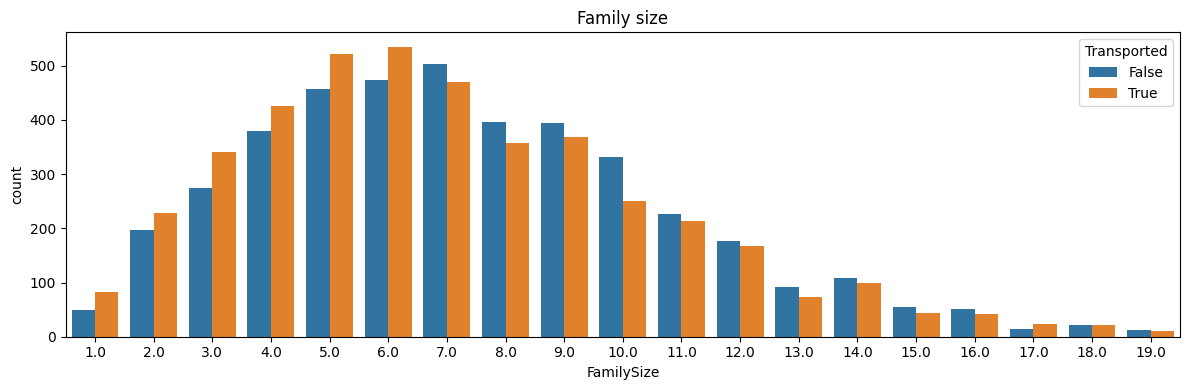

In [24]:
plt.figure(figsize=(12, 4))
sns.countplot(data=train, x='FamilySize', hue='Transported')
plt.title('Family size')

plt.tight_layout()
plt.show()

## Fill in missing values

Combine the training and testing set to make it easier to fill in missing values. Once filling in the missing values is done, resplit the data into training and testing sets.

In [25]:
# y denotes the label (target variable) for this data
# X denotes the feature maxtrix

y = train['Transported'].copy().astype(int)
X = train.drop('Transported', axis=1).copy()

# Concatenate dataframes
data = pd.concat([X, test], axis=0).reset_index(drop=True)

In [26]:
missing_count = train.isna().sum()
missing_per = missing_count / len(train) * 100

In [27]:
result = pd.DataFrame({"Missing Count": missing_count, "Missing %": missing_per})

In [28]:
result = result[result["Missing Count"] > 0]
result

,Missing Count,Missing %
HomePlanet,201,2.312205
CryoSleep,217,2.496261
Destination,182,2.093639
Age,179,2.059128
VIP,203,2.335212
RoomService,181,2.082135
FoodCourt,183,2.105142
ShoppingMall,208,2.392730
Spa,183,2.105142
VRDeck,188,2.162660


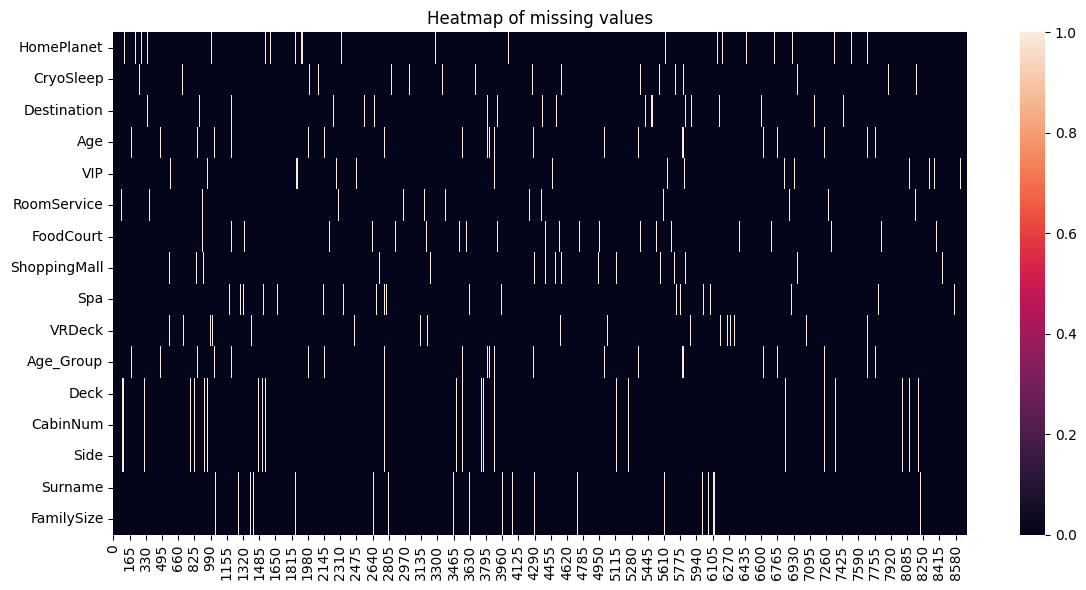

In [49]:
# Heatmap of missing values
plt.figure(figsize=(12, 6))
sns.heatmap(train[result.index].isna().T)
plt.title('Heatmap of missing values')

plt.tight_layout()
plt.show()

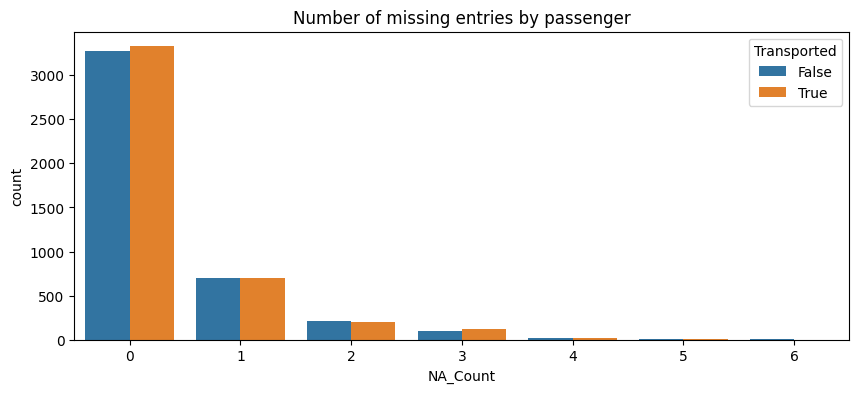

In [30]:
# Countplot of number of missing values by passenger
# temporarily get an NA count of the rows 
train['NA_Count'] = train.isna().sum(axis=1)

plt.figure(figsize=(10,4))
sns.countplot(data=train, x='NA_Count', hue='Transported')
plt.title('Number of missing entries by passenger')

# remove NA count once the plot is created
train.drop('NA_Count', axis=1, inplace=True)

### Insights

We should try to fill in the missing rows rather than drop them since most of the missing values are isolated. We can fill in missing values if there is a relationship between PassengerId and other features. 

look at the joint distribution of features. One possible question to answer is do passengers from the same group tend to come from the same family?

In [34]:
# Joint distribution of Group and HomePlanet
joint_group_homeplanet = data.groupby(['Group','HomePlanet'])['HomePlanet'].size().unstack().fillna(0)
joint_group_homeplanet.head()

HomePlanet,Earth,Europa,Mars
Group,,,
1,0.0,1.0,0.0
2,1.0,0.0,0.0
3,0.0,2.0,0.0
4,1.0,0.0,0.0
5,1.0,0.0,0.0


Text(0.5, 0, 'Unique home planets in group')

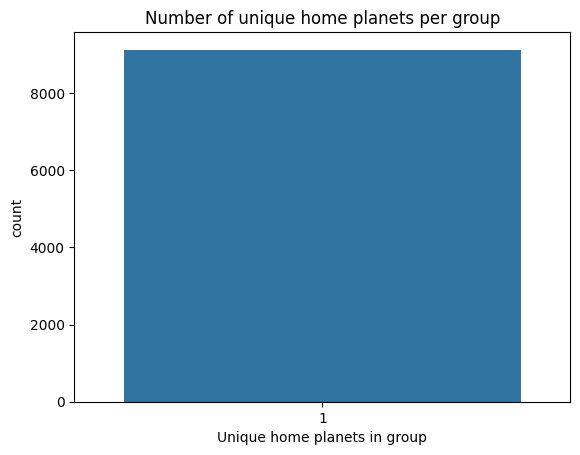

In [35]:
n_planets = (joint_group_homeplanet > 0).sum(axis=1)

sns.countplot(x=n_planets)
plt.title('Number of unique home planets per group')
plt.xlabel('Unique home planets in group')

In [39]:
# Missing values before
HP_bef=data['HomePlanet'].isna().sum()

# Passengers with missing HomePlanet and in a group with known HomePlanet
GHP_index=data[data['HomePlanet'].isna()][(data[data['HomePlanet'].isna()]['Group']).isin(joint_group_homeplanet.index)].index

# Fill corresponding missing values
data.loc[GHP_index,'HomePlanet']=data.iloc[GHP_index,:]['Group'].map(lambda x: joint_group_homeplanet.idxmax(axis=1)[x])

# Print number of missing values left
print('HomePlanet missing values before:', HP_bef)
print('HomePlanet missing values after:', data['HomePlanet'].isna().sum())

HomePlanet missing values before: 157
HomePlanet missing values after: 157


<Axes: xlabel='Deck', ylabel='HomePlanet'>

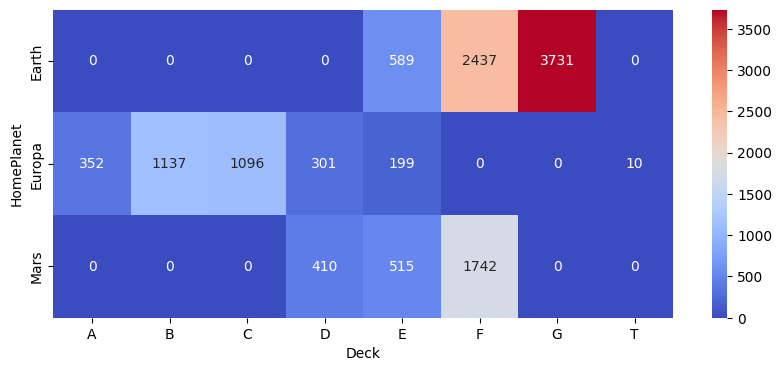

In [43]:
# Joint distribution of Deck and HomePlanet
CDHP_gb=data.groupby(['Deck','HomePlanet'])['HomePlanet'].size().unstack().fillna(0)

# Heatmap of missing values
plt.figure(figsize=(10,4))
sns.heatmap(CDHP_gb.T, annot=True, fmt='g', cmap='coolwarm')

### Insights

passengers from deck G came from Earth. Passengers from A, B, C, and T came from Europa. Passengers from D, E, F came from a mix of planets.

In [46]:
# Missing values before
missing_homeplanet = data['HomePlanet'].isna().sum()
missing_homeplanet

np.int64(157)

In [47]:
data.loc[(data['HomePlanet'].isna()) & (data['Deck'].isin(['A', 'B', 'C', 'T'])), 'HomePlanet'] = 'Europa'
data.loc[(data['HomePlanet'].isna()) & (data['Deck'] == 'G'), 'HomePlanet'] = 'Earth'

In [48]:
print('HomePlanet missing values before:', missing_homeplanet)
print('HomePlanet missing values after:', data['HomePlanet'].isna().sum())

HomePlanet missing values before: 157
HomePlanet missing values after: 94


HomePlanet and Surname

# 3. Train Test Split

In [32]:
from sklearn.model_selection import train_test_split

train_set, valid_set = train_test_split(train, test_size=0.20)

y_train = train_set.pop("Transported")
y_valid = valid_set.pop("Transported")

X_train = train_set
X_valid = valid_set

# 4. Preprocessing

In [33]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

cat_cols = ["HomePlanet", "Destination", "Deck", "Side"]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), 
         cat_cols)
    ],
    remainder="passthrough"
)

In [34]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{fea

In [35]:
preprocessor.set_output(transform="pandas")
X_transformed = preprocessor.fit_transform(X_train)

# 4. Create a Random Forest Classifier

In [37]:
from sklearn.ensemble import RandomForestClassifier

model = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", RandomForestClassifier(random_state=101, n_jobs=-1))
])

In [38]:
model["clf"]

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [39]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(5, shuffle=True, random_state=42)
print("CV accuracy:", cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy").mean())

CV accuracy: 0.8015550119214477


In [40]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sp

# Submission

In [42]:
# loading the testing set
test_frame = pd.read_csv("test.csv")
submission_id = test_frame.PassengerId

# Replace NaN values with zero
test_frame[['VIP', 'CryoSleep']] = test_frame[['VIP', 'CryoSleep']].fillna(value=0)

test_frame[["Deck", "CabinNum", "Side"]] = test_frame["Cabin"].str.split("/", expand=True)
test_frame = test_frame.drop('Cabin', axis=1)

test_frame[["VIP", "CryoSleep"]] = test_frame[["VIP", "CryoSleep"]].astype("int")

# add total spend column
test_frame["TotalSpend"] = test_frame[["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]].sum(axis=1)

test_frame["Group"] = test_frame["PassengerId"].str[:4].astype(int)
test_frame["GroupSize"] = test_frame.groupby("Group")["PassengerId"].transform("count")

# get predictions
predictions = model.predict(test_frame)
n_predictions = (predictions > 0.5).astype(bool)

output = pd.DataFrame({'PassengerId': submission_id,
                       'Transported': n_predictions.squeeze()})

In [43]:
test_frame.head()

,PassengerId,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Deck,CabinNum,Side,TotalSpend,Group,GroupSize
0,0013_01,Earth,1,TRAPPIST-1e,27.0,0,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning,G,3,S,0.0,13,1
1,0018_01,Earth,0,TRAPPIST-1e,19.0,0,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers,F,4,S,2832.0,18,1
2,0019_01,Europa,1,55 Cancri e,31.0,0,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus,C,0,S,0.0,19,1
3,0021_01,Europa,0,TRAPPIST-1e,38.0,0,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter,C,1,S,7418.0,21,1
4,0023_01,Earth,0,TRAPPIST-1e,20.0,0,10.0,0.0,635.0,0.0,0.0,Brence Harperez,F,5,S,645.0,23,1


In [44]:
print(output)

     PassengerId  Transported
0        0013_01         True
1        0018_01        False
2        0019_01         True
3        0021_01         True
4        0023_01         True
...          ...          ...
4272     9266_02         True
4273     9269_01        False
4274     9271_01         True
4275     9273_01         True
4276     9277_01        False

[4277 rows x 2 columns]


In [45]:
sample_submission_df = pd.read_csv('sample_submission.csv')
sample_submission_df['Transported'] = n_predictions
sample_submission_df.to_csv('submission.csv', index=False)
sample_submission_df.head()

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True
